# Assignment 3: label-free selection results

This notebook rebuilds every table and figure in the Assignment 3 manuscript from saved result files. It does not rerun any experiment. Each number traces back to a folder under `results/` holding a `metrics.csv` and a `params.json` with that run's settings, seed and candidate grid.

| Display | Produced by |
|---|---|
| Table I, the datasets | `scripts/dataset_facts.py` |
| Table II, ARI under each label-free rule | `scripts/run_rule_stability.py`, `run_rule_silhouette.py`, `run_rule_default.py` |
| Table III, the cluster counts chosen | the same runs |
| Figure 1, stability against cluster count | the stability runs |
| The mechanism numbers | `scripts/a3_report.py` |

The environment is `envs/scminer.yml`. Data live outside the repository, as described in `README.md`.

In [1]:
import json, sys
import pandas as pd
from IPython.display import Image, display
from scminer_clust.paths import REPO, RESULTS
sys.path.insert(0, str(REPO / "scripts"))
import a3_report
a3_report.main()   # rewrites latex/tables/a3_*.tex, the figure, and results/a3_report_numbers.json
nums = json.loads((RESULTS / "a3_report_numbers.json").read_text())

mechanism: share of settings tied with the best {'leiden_pca': 0.221, 'mica': 0.375}
mechanism: mean span of cluster counts among tied settings {'leiden_pca': 2.6, 'mica': 7.3}
MICA default k=4: ARI 0.802 where the true count is 3 to 5, 0.579 outside


wrote the stability curve figure
default              MICA 0.727  Leiden 0.514  MICA wins 7 of 9
silhouette_shared    MICA 0.595  Leiden 0.564  MICA wins 6 of 9
stability_finest     MICA 0.682  Leiden 0.632  MICA wins 5 of 9
stability_most       MICA 0.473  Leiden 0.635  MICA wins 3 of 9
wrote tables to /home/ugdf8/coursework/26Fall/Clustering_Algorithms/scminer-clustering/latex/tables


## Table II. ARI of the partition each rule chose

No reference labels are used to make the choice. Median over the repeats, with the observed range.

In [2]:
rows = []
for rule in ["default", "silhouette_shared", "stability_finest", "stability_most"]:
    if rule not in nums or "per_dataset" not in nums[rule]:
        continue
    per = nums[rule]["per_dataset"]
    for ds in per["mica"]:
        rows.append({"rule": rule, "dataset": ds, "MICA": per["mica"][ds],
                     "Leiden": per["leiden_pca"][ds],
                     "MICA minus Leiden": round(per["mica"][ds] - per["leiden_pca"][ds], 3)})
table2 = pd.DataFrame(rows).pivot(index="dataset", columns="rule",
                                  values=["MICA", "Leiden", "MICA minus Leiden"])
table2.round(3)

MICA                                                    \
rule          default silhouette_shared stability_finest stability_most   
dataset                                                                   
buettner        0.919             0.474            0.934          0.474   
chung           0.656             0.551            0.474          0.100   
goolam          0.582             0.630            0.593          0.630   
klein           0.980             0.501            0.682          0.501   
kolodziejczyk   0.834             0.726            0.724          0.630   
pollen          0.493             0.942            0.898          0.087   
usoskin         0.839             0.347            0.818          0.818   
yan             0.766             0.794            0.496          0.496   
zeisel          0.478             0.386            0.518          0.518   

               Leiden                                                    \
rule          default silhouette_shared stability_finest stability_most   
dataset                                                                   
buettner        0.236             0.154            0.232          0.134   
chung           0.567             0.046            0.130          0.130   
goolam          0.349             0.619            0.429          0.619   
klein           0.469             0.859            0.974          0.859   
kolodziejczyk   0.525             0.525            0.838          0.838   
pollen          0.865             0.870            0.755          0.755   
usoskin         0.393             0.761            0.633          0.757   
yan             0.845             0.766            0.845          0.766   
zeisel          0.378             0.472            0.857          0.857   

              MICA minus Leiden                                     \
rule                    default silhouette_shared stability_finest   
dataset                                                              
buettner                  0.682             0.321            0.702   
chung                     0.089             0.505            0.344   
goolam                    0.233             0.011            0.164   
klein                     0.510            -0.358           -0.291   
kolodziejczyk             0.309             0.201           -0.113   
pollen                   -0.372             0.072            0.143   
usoskin                   0.446            -0.414            0.185   
yan                      -0.080             0.028           -0.349   
zeisel                    0.100            -0.086           -0.339   

                              
rule          stability_most  
dataset                       
buettner               0.340  
chung                 -0.029  
goolam                 0.011  
klein                 -0.358  
kolodziejczyk         -0.208  
pollen                -0.668  
usoskin                0.061  
yan                   -0.269  
zeisel                -0.339

## Summary across rules

The spread across rules is the result: it is larger for MICA than for the baseline, and larger than the gap between the methods under any one rule.

In [3]:
summary = pd.DataFrame([
    {"rule": r, "MICA mean": nums[r]["mica_mean"], "Leiden mean": nums[r]["leiden_mean"],
     "MICA wins": f'{nums[r]["mica_wins"]} of {nums[r]["n_datasets"]}'}
    for r in ["default", "silhouette_shared", "stability_finest", "stability_most"]
    if r in nums and "mica_mean" in nums[r]])
spread = summary[["MICA mean", "Leiden mean"]].max() - summary[["MICA mean", "Leiden mean"]].min()
display(summary.round(3))
print("spread across rules:", spread.round(3).to_dict())

,rule,MICA mean,Leiden mean,MICA wins
0,default,0.727,0.514,7 of 9
1,silhouette_shared,0.595,0.564,6 of 9
2,stability_finest,0.682,0.632,5 of 9
3,stability_most,0.473,0.635,3 of 9


spread across rules: {'MICA mean': 0.255, 'Leiden mean': 0.121}


## Why the rules disagree

Among settings the stability rule scores within 0.01 of its best, how wide a span of cluster counts remains?

In [4]:
mech = pd.read_csv(RESULTS / "a3_mechanism.csv")
display(mech[["ds", "method", "share_tied", "k_tied_min", "k_tied_max", "chosen_k", "true_k"]])
print({k: v for k, v in nums["mechanism"].items() if k != "table"})

,ds,method,share_tied,k_tied_min,k_tied_max,chosen_k,true_k
0,buettner,leiden_pca,0.027,2,3,3.0,3
1,buettner,mica,0.105,2,3,3.0,3
2,chung,leiden_pca,0.608,3,7,3.0,4
3,chung,mica,0.509,2,12,11.0,4
4,goolam,leiden_pca,0.158,2,3,3.0,5
5,goolam,mica,0.298,2,8,6.0,5
6,klein,leiden_pca,0.037,3,4,4.0,4
7,klein,mica,0.263,2,6,2.5,4
8,kolodziejczyk,leiden_pca,0.212,4,7,4.0,3
9,kolodziejczyk,mica,0.211,2,5,4.0,3


{'tie_window': 0.01, 'mean_share_tied': {'leiden_pca': 0.221, 'mica': 0.375}, 'mean_k_span_among_tied': {'leiden_pca': 2.6, 'mica': 7.3}, 'mean_spread': {'leiden_pca': 0.527, 'mica': 0.382}, 'mean_spearman_stability_ari': {'leiden_pca': 0.499, 'mica': 0.645}, 'spearman_spread_vs_excess_clusters': {'leiden_pca': -0.21, 'mica': -0.008}, 'n_datasets': 9}


## Figure 1. Stability and accuracy against the number of clusters

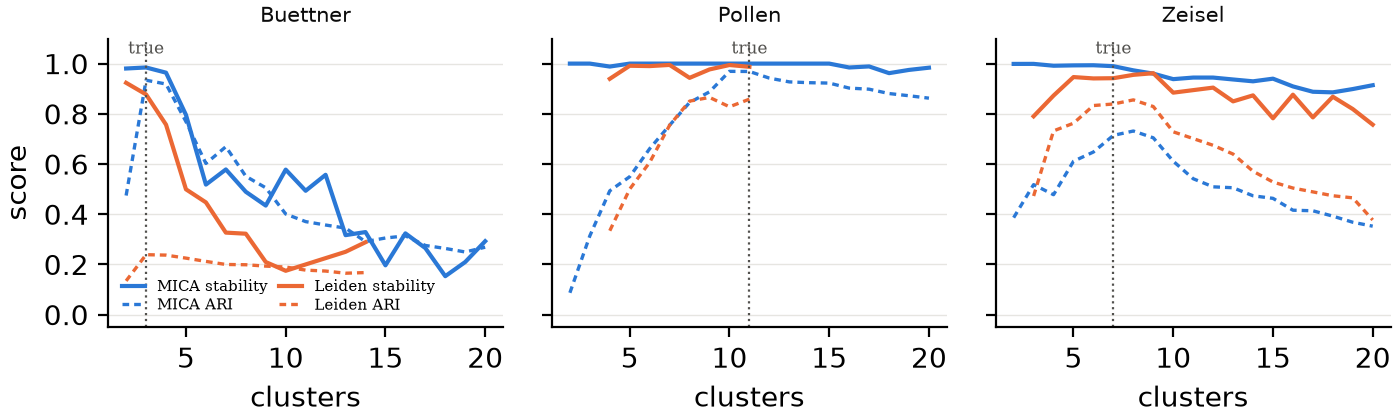

In [5]:
display(Image(filename=str(REPO / "latex" / "figures" / "a3_stability_curve.png"), width=900))

## MICA's shipped default against this benchmark's cluster counts

In [6]:
print(json.dumps(nums.get("mica_default", {}), indent=1))
print("true cluster counts:", sorted(nums["true_k"].values()))

{
 "shipped_k": 4,
 "source": "MICA/mica_mds.py, -nck default",
 "median_true_k_of_benchmark": 4,
 "datasets_with_true_k_4": [
  "chung",
  "usoskin",
  "klein"
 ],
 "mean_ari_true_k_3_to_5": 0.802,
 "mean_ari_true_k_outside": 0.579,
 "n_near": 6,
 "n_far": 3
}
true cluster counts: [3, 3, 4, 4, 4, 5, 7, 7, 8, 11]
